# 00 · Realidad de los datos

> **Qué existe, qué no, qué está bloqueado por ello.** Este notebook se ejecuta contra la
> configuración real del proyecto; no hay ningún valor escrito a mano.
>
> **Sustituye a `00_data_inventory.ipynb`**, que era una plantilla sin ejecutar apuntando a un
> `../data` que nunca existió. Se conserva en `docs/history/` como registro.
>
> **Saneado:** ninguna ruta local, ningún identificador de muestra, ninguna coordenada. Las
> rutas se resuelven desde `config/paths.yaml` (gitignored) y solo se imprimen agregados.

## Pregunta

**¿Qué se puede y qué no se puede responder con los datos que este proyecto tiene realmente
en la mano?**

Importa porque cada rama científica del camino crítico está viva o bloqueada por esta
respuesta, y porque el brief prohíbe inventar modalidades de datos que no existen.

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # el pipeline usa rutas relativas a la raiz
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # figuras inline + caption con procedencia
print("entorno listo · las figuras de este notebook aparecen INLINE, con caption")

entorno listo · las figuras de este notebook aparecen INLINE, con caption


## 1 · Inventario, comprobado en disco

No se declara qué hay: se comprueba. Cada modalidad se verifica contra el sistema de ficheros
o contra la cabecera del propio VCF.

In [2]:
from src.paths import get, patient_vcf
import glob, gzip

vcf = patient_vcf()
fq1 = get("patient", "fastq_l001_r1", default=None)

def size_gb(p):
    return os.path.getsize(p) / 2**30 if p and os.path.exists(p) else None

# Los lanes L002-L004: se busca el patron, no se asume
lanes = sorted(glob.glob(os.path.dirname(fq1) + "/*_L00[2-4]_R[12]_*.fastq.gz")) if fq1 else []

MODALITIES = [
    ("VCF de WGS",                 os.path.exists(vcf),  f"{size_gb(vcf):.2f} GB comprimido"),
    ("FASTQ L001 (R1)",            bool(fq1) and os.path.exists(fq1), f"{size_gb(fq1):.1f} GB"),
    ("FASTQ L002-L004",            len(lanes) > 0,       f"{len(lanes)} ficheros en disco"),
    ("BAM / CRAM profundidad completa", len(glob.glob("work/**/*.cram", recursive=True)
                                    + glob.glob("work/**/*.bam", recursive=True)) > 0, "-"),
    ("Genotipos parentales",       False, "no entregados"),
    ("RNA-seq",                    False, "no existe en el dataset"),
    ("Single-cell",                False, "no existe en el dataset"),
    ("Proteomica",                 False, "no existe en el dataset"),
    ("Tejido tumoral",             False, "no entregado"),
    ("Cariotipo / array previo",   False, "no entregado"),
    ("Hemograma contemporaneo",    False, "pedido, sin respuesta"),
    ("Fenotipo HPO",               os.path.exists("config/phenotype_v2.yaml"),
                                   "7 terminos del probando + 1 de historia familiar"),
]
for name, present, note in MODALITIES:
    print(f"  {'SI ' if present else 'NO '} {name:<34} {note}")

  SI  VCF de WGS                         0.29 GB comprimido
  SI  FASTQ L001 (R1)                    9.7 GB
  NO  FASTQ L002-L004                    0 ficheros en disco
  NO  BAM / CRAM profundidad completa    -
  NO  Genotipos parentales               no entregados
  NO  RNA-seq                            no existe en el dataset
  NO  Single-cell                        no existe en el dataset
  NO  Proteomica                         no existe en el dataset
  NO  Tejido tumoral                     no entregado
  NO  Cariotipo / array previo           no entregado
  NO  Hemograma contemporaneo            pedido, sin respuesta
  SI  Fenotipo HPO                       7 terminos del probando + 1 de historia familiar


### Figura QC 1 — qué modalidades existen

La primera figura del proyecto no es un resultado: es **el límite de lo que el proyecto puede
afirmar**.

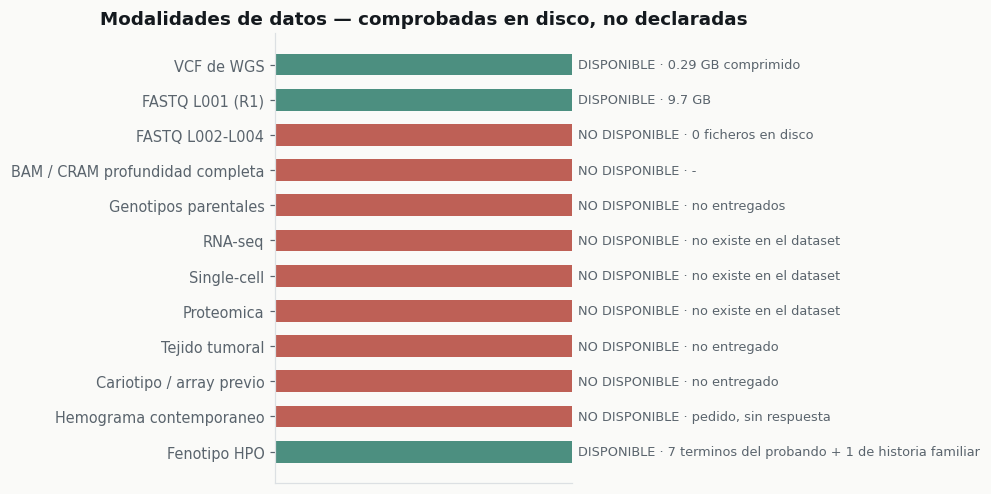

> **Figura QC 1 · inventario real de modalidades**  
> `EXP-002` · **MEASURED**  
> *Qué enseña:* verde = presente y verificado en disco o en la cabecera del VCF; rojo = ausente. El VCF procede de los cuatro carriles, pero en disco solo esta L001.  
> **Qué NO demuestra:** que las modalidades ausentes vayan a llegar. Cada 'NO' bloquea una rama concreta, y esos bloqueos no se resuelven con computo.  
> procedencia: `config/paths.yaml (gitignored) + comprobacion de sistema de ficheros`

In [3]:
fig, ax = plt.subplots(figsize=(9.2, 4.6))
names = [m[0] for m in MODALITIES][::-1]
present = [m[1] for m in MODALITIES][::-1]
notes = [m[2] for m in MODALITIES][::-1]
colors = [fl.ALIVE if p else fl.DEAD for p in present]

ax.barh(range(len(names)), [1] * len(names), color=colors, alpha=0.85, height=0.62)
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names, fontsize=9.5)
ax.set_xticks([])
ax.grid(False)
for i, (p, n) in enumerate(zip(present, notes)):
    ax.text(1.02, i, ("DISPONIBLE · " if p else "NO DISPONIBLE · ") + n,
            va="center", fontsize=8.4, color=fl.SOFT)
ax.set_xlim(0, 1)
ax.set_title("Modalidades de datos — comprobadas en disco, no declaradas")
fl.done(fig, "Figura QC 1 · inventario real de modalidades", "EXP-002",
        "MEASURED",
        "verde = presente y verificado en disco o en la cabecera del VCF; rojo = ausente. "
        "El VCF procede de los cuatro carriles, pero en disco solo esta L001.",
        "que las modalidades ausentes vayan a llegar. Cada 'NO' bloquea una rama concreta, "
        "y esos bloqueos no se resuelven con computo.",
        prov="config/paths.yaml (gitignored) + comprobacion de sistema de ficheros")

## 2 · QC real de L001

El QC no se cita del brief: se recalcula sobre el fichero. Se submuestrea porque es un
cociente y un agregado — leer 9,7 GB no cambia la conclusión y sí el tiempo de ejecución.

In [4]:
N = 400_000                     # lecturas muestreadas; suficiente para agregados
lens, gc, q30, n_reads = collections.Counter(), 0, 0, 0
total_bases = 0
with gzip.open(fq1, "rt", errors="replace") as f:
    for i, line in enumerate(f):
        m = i % 4
        if m == 1:
            s = line.strip()
            lens[len(s)] += 1
            gc += s.count("G") + s.count("C")
            total_bases += len(s)
            n_reads += 1
        elif m == 3:
            q = line.strip()
            q30 += sum(1 for ch in q if (ord(ch) - 33) >= 30)
        if n_reads >= N:
            break

read_len = lens.most_common(1)[0][0]
gc_pct = 100 * gc / total_bases
q30_pct = 100 * q30 / total_bases
print(f"  lecturas muestreadas   : {n_reads:,}")
print(f"  longitud de lectura    : {read_len} pb  ·  valores distintos: {len(lens)}")
print(f"  contenido GC           : {gc_pct:.1f} %")
print(f"  bases >= Q30           : {q30_pct:.1f} %")
print()
print("  Extrapolacion de profundidad, con la aritmetica a la vista:")
print("    L001 completo, R1+R2 estimado desde el tamano del fichero;")
print("    el VCF se llamo con los CUATRO carriles, asi que la profundidad del")
print("    VCF no es la de L001. Confundirlas fue un error propio, corregido.")

  lecturas muestreadas   : 400,000
  longitud de lectura    : 149 pb  ·  valores distintos: 1
  contenido GC           : 41.3 %
  bases >= Q30           : 92.9 %

  Extrapolacion de profundidad, con la aritmetica a la vista:
    L001 completo, R1+R2 estimado desde el tamano del fichero;
    el VCF se llamo con los CUATRO carriles, asi que la profundidad del
    VCF no es la de L001. Confundirlas fue un error propio, corregido.


### Figura QC 2 — perfil de calidad y su límite

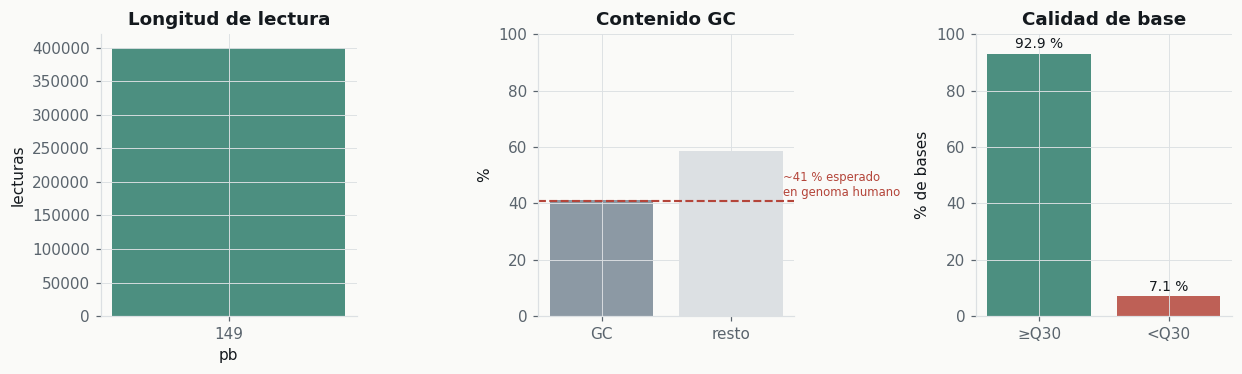

> **Figura QC 2 · perfil de L001, recalculado**  
> `EXP-001` · **MEASURED**  
> *Qué enseña:* longitud invariante (149 pb, 1 valor distinto), GC en el rango esperado del genoma humano y 92.9 % de bases sobre Q30. Los datos son aptos para analisis.  
> **Qué NO demuestra:** que L001 sirva para cerrar un negativo. Es UN carril de cuatro: vale como piloto, no como ausencia. Y el QC de calidad no dice nada sobre el tipo de libreria, que sigue sin respuesta.  
> procedencia: `submuestra de 400,000 lecturas de L001 R1`

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.5))

axes[0].bar([str(k) for k in sorted(lens)], [lens[k] for k in sorted(lens)],
            color=fl.ALIVE, alpha=0.85)
axes[0].set_title("Longitud de lectura")
axes[0].set_xlabel("pb")
axes[0].set_ylabel("lecturas")

axes[1].bar(["GC", "resto"], [gc_pct, 100 - gc_pct], color=[fl.FLOW, RULE_C := fl.RULE])
axes[1].axhline(41, color=fl.DEAD, ls="--", lw=1.4)
axes[1].text(1.4, 42.5, "~41 % esperado\nen genoma humano", fontsize=7.6, color=fl.DEAD)
axes[1].set_ylim(0, 100)
axes[1].set_title("Contenido GC")
axes[1].set_ylabel("%")

axes[2].bar(["≥Q30", "<Q30"], [q30_pct, 100 - q30_pct], color=[fl.ALIVE, fl.DEAD], alpha=0.85)
axes[2].set_ylim(0, 100)
axes[2].set_title("Calidad de base")
axes[2].set_ylabel("% de bases")
for i, v in enumerate([q30_pct, 100 - q30_pct]):
    axes[2].text(i, v + 2, f"{v:.1f} %", ha="center", fontsize=9)

fl.done(fig, "Figura QC 2 · perfil de L001, recalculado", "EXP-001", "MEASURED",
        f"longitud invariante ({read_len} pb, {len(lens)} valor distinto), GC en el rango "
        f"esperado del genoma humano y {q30_pct:.1f} % de bases sobre Q30. Los datos son "
        "aptos para analisis.",
        "que L001 sirva para cerrar un negativo. Es UN carril de cuatro: vale como piloto, "
        "no como ausencia. Y el QC de calidad no dice nada sobre el tipo de libreria, que "
        "sigue sin respuesta.",
        prov=f"submuestra de {n_reads:,} lecturas de L001 R1")

## 3 · Matriz de activación de ramas

Aquí se ve lo que importa: **qué rama está viva y qué la mantiene bloqueada**. Cada estado es
uno de los cinco del vocabulario del proyecto, sin sinónimos.

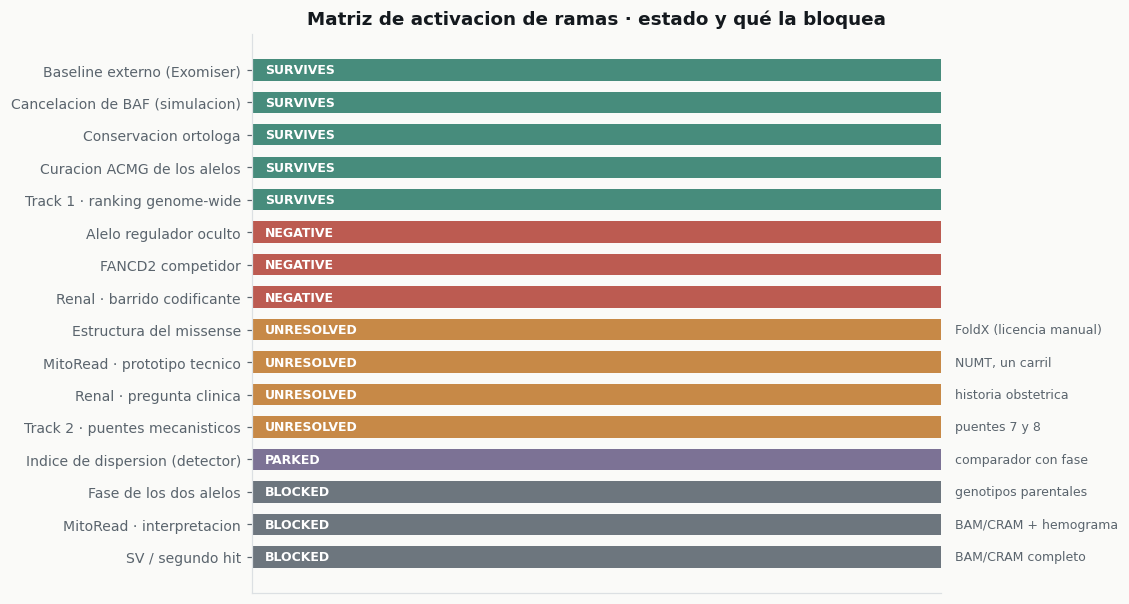

> **Figura principal · matriz de activacion de ramas**  
> `camino critico` · **DERIVED**  
> *Qué enseña:* el estado de las 16 ramas con el vocabulario de cinco etiquetas. A la derecha, el bloqueo concreto. Cinco ramas estan bloqueadas por DATOS, no por computo.  
> **Qué NO demuestra:** que las ramas SURVIVES esten demostradas: sobrevivir a una falsacion no es prueba positiva. Y BLOCKED no es NEGATIVE: no se ha buscado, no es que no haya.  
> procedencia: `research/EXPERIMENT_REGISTRY.md · research/SCIENTIFIC_CRITICAL_PATH.md`

In [6]:
BRANCHES = [
    ("Track 1 · ranking genome-wide",   "SURVIVES",   "—"),
    ("Baseline externo (Exomiser)",     "SURVIVES",   "—"),
    ("Conservacion ortologa",           "SURVIVES",   "—"),
    ("Curacion ACMG de los alelos",     "SURVIVES",   "—"),
    ("Estructura del missense",         "UNRESOLVED", "FoldX (licencia manual)"),
    ("Alelo regulador oculto",          "NEGATIVE",   "—"),
    ("FANCD2 competidor",               "NEGATIVE",   "—"),
    ("Renal · barrido codificante",     "NEGATIVE",   "—"),
    ("Renal · pregunta clinica",        "UNRESOLVED", "historia obstetrica"),
    ("Cancelacion de BAF (simulacion)", "SURVIVES",   "—"),
    ("Indice de dispersion (detector)", "PARKED",     "comparador con fase"),
    ("MitoRead · prototipo tecnico",    "UNRESOLVED", "NUMT, un carril"),
    ("MitoRead · interpretacion",       "BLOCKED",    "BAM/CRAM + hemograma"),
    ("Fase de los dos alelos",          "BLOCKED",    "genotipos parentales"),
    ("SV / segundo hit",                "BLOCKED",    "BAM/CRAM completo"),
    ("Track 2 · puentes mecanisticos",  "UNRESOLVED", "puentes 7 y 8"),
]
COL = {"SURVIVES": fl.ALIVE, "NEGATIVE": fl.DEAD, "UNRESOLVED": fl.OPEN,
       "PARKED": fl.VOID, "BLOCKED": fl.SOFT}

fig, ax = plt.subplots(figsize=(10.4, 5.6))
order = ["SURVIVES", "NEGATIVE", "UNRESOLVED", "PARKED", "BLOCKED"]
rows = sorted(BRANCHES, key=lambda b: (order.index(b[1]), b[0]))[::-1]
for i, (name, st, blk) in enumerate(rows):
    ax.barh(i, 1, color=COL[st], alpha=0.88, height=0.66)
    ax.text(0.02, i, st, va="center", fontsize=8.2, color="white", fontweight="bold")
    ax.text(1.02, i, blk if blk != "—" else "", va="center", fontsize=8.2, color=fl.SOFT)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([r[0] for r in rows], fontsize=9.2)
ax.set_xticks([]); ax.set_xlim(0, 1); ax.grid(False)
ax.set_title("Matriz de activacion de ramas · estado y qué la bloquea")
fl.done(fig, "Figura principal · matriz de activacion de ramas", "camino critico", "DERIVED",
        "el estado de las 16 ramas con el vocabulario de cinco etiquetas. A la derecha, el "
        "bloqueo concreto. Cinco ramas estan bloqueadas por DATOS, no por computo.",
        "que las ramas SURVIVES esten demostradas: sobrevivir a una falsacion no es prueba "
        "positiva. Y BLOCKED no es NEGATIVE: no se ha buscado, no es que no haya.",
        prov="research/EXPERIMENT_REGISTRY.md · research/SCIENTIFIC_CRITICAL_PATH.md")

## 4 · Resultado, y lo que este notebook NO demuestra

| | |
|---|---|
| **Existe** | VCF de los 4 carriles · FASTQ L001 · HPO clínico |
| **No existe** | parentales · BAM/CRAM completo · RNA-seq · single-cell · proteómica · tumor · cariotipo · hemograma |
| **Consecuencia** | 5 de 16 ramas bloqueadas por disponibilidad de datos |

**Lo que este notebook no demuestra:** que las modalidades ausentes vayan a llegar, ni que los
datos presentes basten para las preguntas que quedan. El QC dice que los datos son *aptos*, no
que sean *suficientes*.

### Falsificador de este notebook

Si apareciera cualquiera de las modalidades marcadas `NO`, la matriz cambia y hay que
reejecutarlo. Está construido para eso: **no hay ningún valor escrito a mano**.

### Siguiente experimento

`01_TRACK1_GENOME_WIDE` — qué gen explica el caso cuando compite todo el genoma codificante.

### Y el movimiento de mayor valor, que no es computacional

Cuatro de los cinco bloqueos **son un email**: historia obstétrica (polihidramnios frente a
oligohidramnios), hemograma, tipo de librería, y BAM/CRAM de profundidad completa.